In [ ]:
import pandas as pd

df = pd.read_csv('ott_viewer_dropoff_retention_us_v1.0.csv')

print("Dataset loaded successfully!")
print("Number of rows and columns:")
print(df.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'ott_viewer_dropoff_retention_us_v1.0.csv'

In [ ]:
# Create a copy of the dataset for preprocessing

df_processed = df.copy()

print("df_processed created successfully!")
print("Shape:", df_processed.shape)

In [ ]:
print(df_processed.head())

In [ ]:
# Data Transformation: Create watch engagement levels

df_processed['watch_engagement_level'] = pd.cut(
    df_processed['avg_watch_percentage'],
    bins=[-float('inf'), 40, 70, float('inf')],
    labels=['Low', 'Medium', 'High']
)

print("Watch engagement levels created successfully!")
print(df_processed['watch_engagement_level'].value_counts())

In [ ]:
print("Final Dataset Shape:", df_processed.shape)

print("\nMissing Values After Preprocessing:")
print(df_processed.isnull().sum().sum())

print("\nDuplicate Rows After Preprocessing:")
print(df_processed.duplicated().sum())

In [ ]:
print("First 5 rows of the dataset:")
print(df.head())

In [ ]:
print("Dataset Information:")
print(df.info())

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

In [ ]:
print("Duplicate Rows:")
print(df.duplicated().sum())

In [ ]:
print("Categorical Columns:")
print(df.select_dtypes(include='object').columns.tolist())

In [ ]:
print("Numerical Columns:")
print(df.select_dtypes(include=['int64', 'float64']).columns.tolist())

In [ ]:
print("Unique values in categorical columns:\n")

for col in df.select_dtypes(include='object').columns:
    print(f"\n{col}:")
    print(df[col].unique()[:20])

In [ ]:
print("Dialogue Density values:")
print(df['dialogue_density'].value_counts())

In [ ]:
print("Numerical Summary:")
print(df.describe())

In [ ]:
print("Numerical Summary:")
print(df.describe())

In [ ]:
df_processed = df.copy()

print("Copy created successfully!")
print(df_processed.shape)

In [ ]:
df_processed = df.copy()

print("Copy created successfully!")
print(df_processed.shape)

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

categorical_columns = [
    'platform',
    'genre',
    'dialogue_density',
    'attention_required',
    'retention_risk'
]

for col in categorical_columns:
    df_processed[col] = label_encoder.fit_transform(df_processed[col])

print("Categorical data encoded successfully!")
print(df_processed[categorical_columns].head())

In [ ]:
from sklearn.preprocessing import StandardScaler

numerical_columns = [
    'episode_duration_min',
    'pacing_score',
    'hook_strength',
    'visual_intensity',
    'avg_watch_percentage',
    'pause_count',
    'rewind_count',
    'cognitive_load',
    'drop_off_probability'
]

scaler = StandardScaler()

df_processed[numerical_columns] = scaler.fit_transform(
    df_processed[numerical_columns]
)

print("Numerical features scaled successfully!")
print(df_processed[numerical_columns].head())

In [ ]:
print("Final Preprocessed Dataset:")
print(df_processed.head())

In [ ]:
print("Final Dataset Shape:", df_processed.shape)

print("\nMissing Values After Preprocessing:")
print(df_processed.isnull().sum().sum())

print("\nDuplicate Rows After Preprocessing:")
print(df_processed.duplicated().sum())

In [ ]:
df_processed.to_csv('JioHotstar_Preprocessed_Dataset.csv', index=False)

print("Processed dataset saved successfully!")

In [ ]:
from google.colab import files

files.download('JioHotstar_Preprocessed_Dataset.csv')

In [ ]:
# Save the preprocessed dataset

df_processed.to_csv(
    'JioHotstar_Preprocessed_Dataset.csv',
    index=False
)

print("Processed dataset saved successfully!")

In [ ]:
from google.colab import files

files.download('JioHotstar_Preprocessed_Dataset.csv')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
df = pd.read_csv("JioHotstar_Preprocessed_Dataset (1).csv")

print("Dataset Loaded Successfully!")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

In [ ]:
print("First 5 Rows:")
display(df.head())

In [ ]:
print("Columns in Dataset:")
print(df.columns.tolist())

In [ ]:
print("Data Types:")
print(df.dtypes)

In [ ]:
# Task 1: Descriptive Analysis - Measures of Central Tendency

numerical_columns = [
    'episode_duration_min',
    'pacing_score',
    'hook_strength',
    'visual_intensity',
    'avg_watch_percentage',
    'pause_count',
    'rewind_count',
    'cognitive_load',
    'drop_off_probability'
]

print("MEAN:")
print(df[numerical_columns].mean())

print("\nMEDIAN:")
print(df[numerical_columns].median())

print("\nMODE:")
print(df[numerical_columns].mode().iloc[0])

In [ ]:
categorical_columns = [
    'platform',
    'genre',
    'dialogue_density',
    'attention_required',
    'retention_risk',
    'watch_engagement_level'
]

print("MODE OF CATEGORICAL ATTRIBUTES:\n")

for column in categorical_columns:
    print(column, ":", df[column].mode()[0])

In [ ]:
# Task 2: Descriptive Analysis - Measures of Dispersion

print("STANDARD DEVIATION:")
print(df[numerical_columns].std())

print("\nVARIANCE:")
print(df[numerical_columns].var())

print("\nRANGE:")
print(df[numerical_columns].max() - df[numerical_columns].min())

print("\nINTERQUARTILE RANGE (IQR):")
print(df[numerical_columns].quantile(0.75) -
      df[numerical_columns].quantile(0.25))

In [ ]:
# Task 3: Correlation Between Numerical Attributes

correlation_matrix = df[numerical_columns].corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

In [ ]:
# Task 3B: Correlation Heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - JioHotstar Dataset")
plt.show()

In [ ]:
# Task 4A: Histogram of Average Watch Percentage

plt.figure(figsize=(10, 6))

plt.hist(
    df['avg_watch_percentage'],
    bins=20,
    edgecolor='black'
)

plt.xlabel("Average Watch Percentage")
plt.ylabel("Number of Records")
plt.title("Distribution of Average Watch Percentage")
plt.show()

In [ ]:
# Task 4B: Boxplot of Episode Duration

plt.figure(figsize=(10, 6))

sns.boxplot(x=df['episode_duration_min'])

plt.xlabel("Episode Duration (minutes)")
plt.title("Boxplot of Episode Duration")
plt.show()

In [ ]:
# Task 4C: Scatter Plot

plt.figure(figsize=(10, 6))

plt.scatter(
    df['avg_watch_percentage'],
    df['drop_off_probability'],
    alpha=0.5
)

plt.xlabel("Average Watch Percentage")
plt.ylabel("Drop-off Probability")
plt.title("Average Watch Percentage vs Drop-off Probability")

plt.show()

In [ ]:
# Import required libraries

import pandas as pd
import numpy as np

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
df = pd.read_csv("JioHotstar_Preprocessed_Dataset (1).csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

In [ ]:
# Display first 5 rows
df.head()

In [ ]:
# Display column names
print(df.columns.tolist())

In [ ]:
# Check basic information about the dataset

print("Dataset Information:")
print("--------------------")

df.info()

In [ ]:
# Check for missing values

print("Missing values in each column:")
print("-------------------------------")

print(df.isnull().sum())

In [ ]:
# Check the target variable

print("Drop-off value counts:")
print("----------------------")

print(df["drop_off"].value_counts())

print("\nDrop-off percentages:")
print("----------------------")

print(df["drop_off"].value_counts(normalize=True) * 100)

In [ ]:
features = [
    "episode_duration_min",
    "pacing_score",
    "hook_strength",
    "visual_intensity",
    "avg_watch_percentage",
    "pause_count",
    "rewind_count",
    "skip_intro",
    "cognitive_load",
    "night_watch_safe"
]

X = df[features]
y = df["drop_off"]

print("Features selected:")
print(features)

print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)

In [ ]:
# Split the dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

In [ ]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

In [ ]:
model.fit(X_train, y_train)

In [ ]:
# Make predictions using the trained Decision Tree

y_pred = model.predict(X_test)

print("Predictions completed successfully!")
print("First 20 predictions:")
print(y_pred[:20])

In [ ]:
# Calculate accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:", accuracy)
print("Decision Tree Accuracy (%):", accuracy * 100)

In [ ]:
# Calculate precision, recall and F1-score

print("Classification Report")
print("---------------------")

print(classification_report(y_test, y_pred))

In [ ]:
# Generate confusion matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print("-----------------")
print(cm)

In [ ]:
# Student-defined function for Decision Tree Classification

def decision_tree_classifier(X_train, X_test, y_train, y_test):

    # Create Decision Tree model
    dt_model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        random_state=42
    )

    # Train the model
    dt_model.fit(X_train, y_train)

    # Make predictions
    predictions = dt_model.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, predictions)

    # Display results
    print("Student-Defined Decision Tree Function")
    print("----------------------------------------")
    print("Accuracy:", accuracy)
    print("Accuracy (%):", accuracy * 100)

    print("\nClassification Report:")
    print(classification_report(y_test, predictions))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    return dt_model, predictions

In [ ]:
# Call the student-defined function

custom_model, custom_predictions = decision_tree_classifier(
    X_train,
    X_test,
    y_train,
    y_test
)

In [ ]:
# Compare Inbuilt and Student-Defined Decision Tree

inbuilt_accuracy = accuracy_score(y_test, y_pred)
custom_accuracy = accuracy_score(y_test, custom_predictions)

print("Comparison of Decision Tree Implementations")
print("--------------------------------------------")

print("Inbuilt Decision Tree Accuracy      :", inbuilt_accuracy)
print("Student-Defined Function Accuracy   :", custom_accuracy)

if inbuilt_accuracy == custom_accuracy:
    print("\nBoth implementations produced the same accuracy.")
else:
    print("\nThe two implementations produced different accuracy values.")

In [ ]:
# Visualize the Decision Tree

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=features,
    class_names=["Retained", "Dropped Off"],
    filled=True,
    rounded=True
)

plt.title("Decision Tree for JioHotstar Drop-off Classification")
plt.show()

In [ ]:
EXPERIMENT 6: K-MEANS CLUSTERING USING PYTHON

Aim:
To implement K-Means clustering on the preprocessed JioHotstar dataset using Python and analyze the resulting viewer/content clusters.

In [ ]:
# Check the JioHotstar dataset for Experiment 6
import pandas as pd

try:
    # Attempt to load the preprocessed dataset
    df = pd.read_csv('JioHotstar_Preprocessed_Dataset (1).csv')
    print("Dataset loaded successfully!")
except FileNotFoundError:
    print("Error: 'JioHotstar_Preprocessed_Dataset (1).csv' file not found. Please upload it first.")

if 'df' in locals() or 'df' in globals():
    print("Dataset Shape:", df.shape)
    print("\nDataset Columns:")
    print(df.columns.tolist())
    print("\nFirst 5 Records:")
    display(df.head())

NameError: name 'df' is not defined

In [ ]:
# Experiment 6 - Load JioHotstar Dataset

import pandas as pd

from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nDataset Columns:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

Saving JioHotstar_Preprocessed_Dataset (1) (1).csv to JioHotstar_Preprocessed_Dataset (1) (1).csv
Dataset loaded successfully!
Dataset Shape: (33171, 24)

Dataset Columns:
['show_id', 'title', 'platform', 'genre', 'release_year', 'season_number', 'episode_number', 'episode_duration_min', 'pacing_score', 'hook_strength', 'dialogue_density', 'visual_intensity', 'avg_watch_percentage', 'pause_count', 'rewind_count', 'skip_intro', 'cognitive_load', 'attention_required', 'night_watch_safe', 'drop_off', 'drop_off_probability', 'retention_risk', 'dataset_version', 'watch_engagement_level']

First 5 Records:


,show_id,title,platform,genre,release_year,season_number,episode_number,episode_duration_min,pacing_score,hook_strength,...,rewind_count,skip_intro,cognitive_load,attention_required,night_watch_safe,drop_off,drop_off_probability,retention_risk,dataset_version,watch_engagement_level
0,66732,Stranger Things,Netflix,Sci-Fi & Fantasy,2016.0,1,1,48,4,5,...,0,0,9,high,0,1,0.649,high,v1.0,Low
1,66732,Stranger Things,Netflix,Sci-Fi & Fantasy,2016.0,1,2,55,5,4,...,3,1,5,medium,0,0,0.473,medium,v1.0,Medium
2,66732,Stranger Things,Netflix,Sci-Fi & Fantasy,2016.0,1,3,51,4,8,...,2,0,9,high,0,0,0.583,medium,v1.0,Medium
3,66732,Stranger Things,Netflix,Sci-Fi & Fantasy,2016.0,1,4,50,4,7,...,1,0,7,high,0,0,0.520,medium,v1.0,Medium
4,66732,Stranger Things,Netflix,Sci-Fi & Fantasy,2016.0,1,5,52,4,3,...,0,1,7,high,0,1,0.638,high,v1.0,Low


In [ ]:
# Experiment 6 - Select features for K-Means clustering

features = [
    'episode_duration_min',
    'pacing_score',
    'hook_strength',
    'visual_intensity',
    'avg_watch_percentage',
    'pause_count',
    'rewind_count',
    'skip_intro',
    'cognitive_load',
    'night_watch_safe'
]

X = df[features]

print("Selected Features:")
print(features)

print("\nShape of selected data:", X.shape)

print("\nFirst 5 rows of selected features:")
display(X.head())

Selected Features:
['episode_duration_min', 'pacing_score', 'hook_strength', 'visual_intensity', 'avg_watch_percentage', 'pause_count', 'rewind_count', 'skip_intro', 'cognitive_load', 'night_watch_safe']

Shape of selected data: (33171, 10)

First 5 rows of selected features:


,episode_duration_min,pacing_score,hook_strength,visual_intensity,avg_watch_percentage,pause_count,rewind_count,skip_intro,cognitive_load,night_watch_safe
0,48,4,5,5,39,3,0,0,9,0
1,55,5,4,8,55,3,3,1,5,0
2,51,4,8,7,46,4,2,0,9,0
3,50,4,7,3,50,4,1,0,7,0
4,52,4,3,4,35,3,0,1,7,0


In [ ]:
# Experiment 6 - Standardize the selected features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled, columns=features)

print("Standardization completed successfully!")

print("\nStandardized data shape:", X_scaled.shape)

print("\nFirst 5 rows of standardized data:")
display(X_scaled.head())

Standardization completed successfully!

Standardized data shape: (33171, 10)

First 5 rows of standardized data:


,episode_duration_min,pacing_score,hook_strength,visual_intensity,avg_watch_percentage,pause_count,rewind_count,skip_intro,cognitive_load,night_watch_safe
0,0.451511,-1.136141,-0.303547,-0.506150,-1.415761,-0.055129,-1.293941,-0.986614,2.120815,-0.127058
1,0.757196,-0.323397,-0.881557,0.998107,-0.143579,-0.055129,0.643583,1.013568,-0.904614,-0.127058
2,0.582519,-1.136141,1.430485,0.496688,-0.859182,0.480515,-0.002259,-0.986614,2.120815,-0.127058
3,0.538850,-1.136141,0.852475,-1.508989,-0.541136,0.480515,-0.648100,-0.986614,0.608100,-0.127058
4,0.626188,-1.136141,-1.459568,-1.007569,-1.733807,-0.055129,-1.293941,1.013568,0.608100,-0.127058


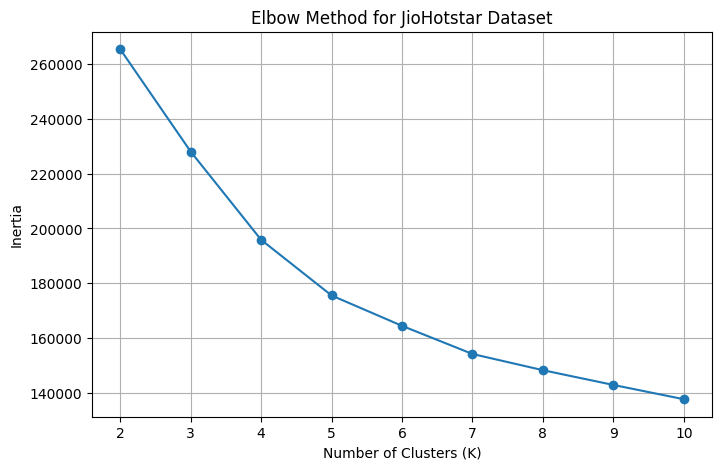

In [ ]:
# Experiment 6 - Elbow Method

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

# Test different values of K
K_values = range(2, 11)

for k in K_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_values, inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for JioHotstar Dataset")
plt.xticks(K_values)
plt.grid(True)
plt.show()

In [ ]:
# Experiment 6 - Apply K-Means Clustering

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to the original dataset
df['Cluster'] = cluster_labels

print("K-Means clustering completed successfully!")

print("\nNumber of records in each cluster:")
print(df['Cluster'].value_counts().sort_index())

K-Means clustering completed successfully!

Number of records in each cluster:
Cluster
0    13101
1    10555
2     8988
3      527
Name: count, dtype: int64


In [ ]:
# Experiment 6 - Clustering Evaluation Metrics

from sklearn.metrics import silhouette_score, davies_bouldin_score

# Silhouette Score
silhouette = silhouette_score(X_scaled, cluster_labels)

# Inertia
inertia_value = kmeans.inertia_

# Davies-Bouldin Score
davies_bouldin = davies_bouldin_score(X_scaled, cluster_labels)

print("Clustering Evaluation Metrics")
print("--------------------------------")
print("Number of Clusters (K):", 4)
print("Silhouette Score:", silhouette)
print("Inertia:", inertia_value)
print("Davies-Bouldin Score:", davies_bouldin)

Clustering Evaluation Metrics
--------------------------------
Number of Clusters (K): 4
Silhouette Score: 0.20837435008280536
Inertia: 195849.28020245346
Davies-Bouldin Score: 1.3747078948175646


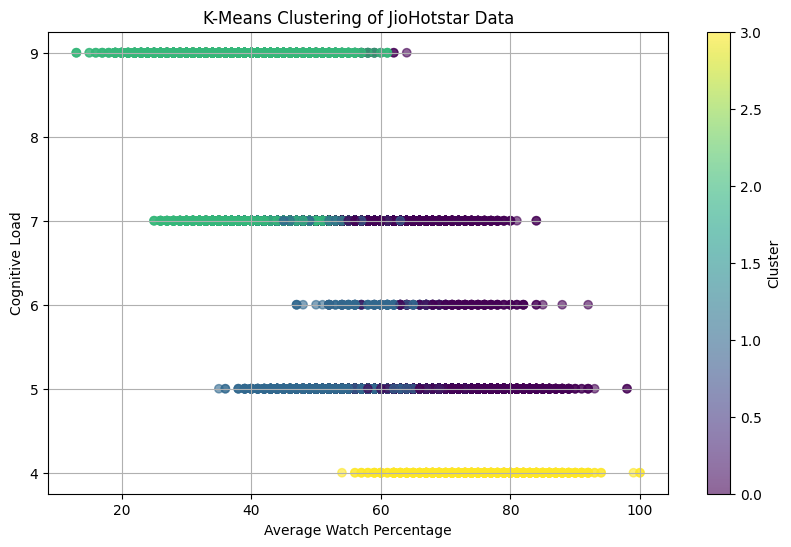

In [ ]:
# Experiment 6 - Visualize K-Means Clusters

plt.figure(figsize=(10, 6))

plt.scatter(
    df['avg_watch_percentage'],
    df['cognitive_load'],
    c=df['Cluster'],
    cmap='viridis',
    alpha=0.6
)

plt.xlabel("Average Watch Percentage")
plt.ylabel("Cognitive Load")
plt.title("K-Means Clustering of JioHotstar Data")

plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()

In [ ]:
# Experiment 6 - Analyze Cluster Characteristics

cluster_summary = df.groupby('Cluster')[features].mean()

print("Mean Characteristics of Each Cluster:")
display(cluster_summary.round(2))

Mean Characteristics of Each Cluster:


,episode_duration_min,pacing_score,hook_strength,visual_intensity,avg_watch_percentage,pause_count,rewind_count,skip_intro,cognitive_load,night_watch_safe
Cluster,,,,,,,,,,
0,37.23,5.75,7.09,5.97,66.44,2.81,1.98,0.00,5.79,0.0
1,37.26,6.03,3.99,6.03,56.00,2.68,2.01,1.00,5.54,0.0
2,38.22,3.99,5.05,6.05,42.59,4.08,2.04,0.62,7.69,0.0
3,46.81,8.00,5.55,5.98,75.74,2.07,1.98,0.47,4.00,1.0


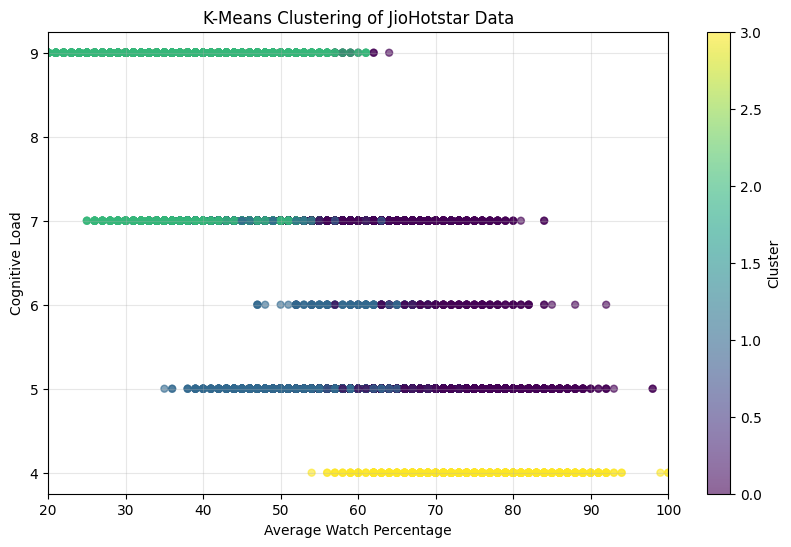

In [ ]:
# Experiment 6 - Final K-Means Cluster Visualization

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    df['avg_watch_percentage'],
    df['cognitive_load'],
    c=df['Cluster'],
    cmap='viridis',
    alpha=0.6,
    s=25
)

plt.xlabel("Average Watch Percentage")
plt.ylabel("Cognitive Load")
plt.title("K-Means Clustering of JioHotstar Data")

plt.colorbar(scatter, label="Cluster")

plt.xlim(20, 100)

plt.grid(True, alpha=0.3)

plt.show()

In [12]:
# EXPERIMENT 9 - ASSOCIATION MINING USING APRIORI

import pandas as pd
import numpy as np

print("Libraries imported successfully.")

Libraries imported successfully.


In [15]:
from google.colab import files

uploaded = files.upload()

Saving JioHotstar_Preprocessed_Dataset (1) (1).csv to JioHotstar_Preprocessed_Dataset (1) (1) (2).csv


In [16]:
# Load JioHotstar dataset

file_name = "JioHotstar_Preprocessed_Dataset (1) (1) (2).csv"

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (33171, 24)

Columns:
['show_id', 'title', 'platform', 'genre', 'release_year', 'season_number', 'episode_number', 'episode_duration_min', 'pacing_score', 'hook_strength', 'dialogue_density', 'visual_intensity', 'avg_watch_percentage', 'pause_count', 'rewind_count', 'skip_intro', 'cognitive_load', 'attention_required', 'night_watch_safe', 'drop_off', 'drop_off_probability', 'retention_risk', 'dataset_version', 'watch_engagement_level']


In [17]:
# Load JioHotstar dataset

file_name = "JioHotstar_Preprocessed_Dataset (1) (1) (2).csv"

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (33171, 24)

Columns:
['show_id', 'title', 'platform', 'genre', 'release_year', 'season_number', 'episode_number', 'episode_duration_min', 'pacing_score', 'hook_strength', 'dialogue_density', 'visual_intensity', 'avg_watch_percentage', 'pause_count', 'rewind_count', 'skip_intro', 'cognitive_load', 'attention_required', 'night_watch_safe', 'drop_off', 'drop_off_probability', 'retention_risk', 'dataset_version', 'watch_engagement_level']


In [18]:
# Check data types and missing values

print("Data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Data types:
show_id                     int64
title                      object
platform                   object
genre                      object
release_year              float64
season_number               int64
episode_number              int64
episode_duration_min        int64
pacing_score                int64
hook_strength               int64
dialogue_density           object
visual_intensity            int64
avg_watch_percentage        int64
pause_count                 int64
rewind_count                int64
skip_intro                  int64
cognitive_load              int64
attention_required         object
night_watch_safe            int64
drop_off                    int64
drop_off_probability      float64
retention_risk             object
dataset_version            object
watch_engagement_level     object
dtype: object

Missing values:
show_id                   0
title                     0
platform                  0
genre                     0
release_year              0
s

In [19]:
# Create behaviour-based items for Association Mining

transaction_df = pd.DataFrame(index=df.index)

transaction_df["High_Watch"] = df["avg_watch_percentage"] >= 70
transaction_df["Strong_Hook"] = df["hook_strength"] >= 7
transaction_df["High_Pacing"] = df["pacing_score"] >= 7
transaction_df["High_Visual_Intensity"] = df["visual_intensity"] >= 7
transaction_df["Skipped_Intro"] = df["skip_intro"] == 1
transaction_df["High_Cognitive_Load"] = df["cognitive_load"] >= 7
transaction_df["Night_Watch_Safe"] = df["night_watch_safe"] == 1

print("Transaction items created successfully!")
print("\nShape:", transaction_df.shape)
print("\nFirst 5 transactions:")
display(transaction_df.head())

Transaction items created successfully!

Shape: (33171, 7)

First 5 transactions:


,High_Watch,Strong_Hook,High_Pacing,High_Visual_Intensity,Skipped_Intro,High_Cognitive_Load,Night_Watch_Safe
0,False,False,False,False,False,True,False
1,False,False,False,True,True,False,False
2,False,True,False,True,False,True,False
3,False,True,False,False,False,True,False
4,False,False,False,False,True,True,False


In [20]:
# Convert True/False values into 1/0 transaction format

transaction_matrix = transaction_df.astype(int)

print("Transaction matrix created successfully!")
print("\nShape:", transaction_matrix.shape)

print("\nFirst 5 transactions:")
display(transaction_matrix.head())

Transaction matrix created successfully!

Shape: (33171, 7)

First 5 transactions:


,High_Watch,Strong_Hook,High_Pacing,High_Visual_Intensity,Skipped_Intro,High_Cognitive_Load,Night_Watch_Safe
0,0,0,0,0,0,1,0
1,0,0,0,1,1,0,0
2,0,1,0,1,0,1,0
3,0,1,0,0,0,1,0
4,0,0,0,0,1,1,0


In [21]:
# Check the frequency of each behaviour item

item_counts = transaction_matrix.sum().sort_values(ascending=False)

item_percentage = (item_counts / len(transaction_matrix) * 100).round(2)

frequency_table = pd.DataFrame({
    "Item_Count": item_counts,
    "Support_Percentage": item_percentage
})

print("Item frequency:")
display(frequency_table)

Item frequency:


,Item_Count,Support_Percentage
High_Cognitive_Load,16878,50.88
Skipped_Intro,16362,49.33
High_Visual_Intensity,14181,42.75
Strong_Hook,11136,33.57
High_Pacing,7361,22.19
High_Watch,5444,16.41
Night_Watch_Safe,527,1.59


In [22]:
# Install mlxtend for Apriori and association rules

!pip install mlxtend -q

print("mlxtend installed successfully!")

mlxtend installed successfully!


In [23]:
from mlxtend.frequent_patterns import apriori, association_rules

# Find frequent itemsets using Apriori
frequent_itemsets = apriori(
    transaction_matrix,
    min_support=0.05,
    use_colnames=True
)

print("Frequent itemsets generated successfully!")
print("Number of frequent itemsets:", len(frequent_itemsets))

display(frequent_itemsets.sort_values(
    by="support",
    ascending=False
))

/usr/local/lib/python3.13/dist-packages/mlxtend/frequent_patterns/fpcommon.py:161: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


Frequent itemsets generated successfully!
Number of frequent itemsets: 22


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
5,0.508818,(High_Cognitive_Load)
4,0.493262,(Skipped_Intro)
3,0.427512,(High_Visual_Intensity)
1,0.335715,(Strong_Hook)
17,0.252419,"(High_Cognitive_Load, Skipped_Intro)"
2,0.221911,(High_Pacing)
16,0.219831,"(High_Visual_Intensity, High_Cognitive_Load)"
15,0.213078,"(High_Visual_Intensity, Skipped_Intro)"
11,0.169727,"(Strong_Hook, High_Cognitive_Load)"
0,0.164119,(High_Watch)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [24]:
# Generate association rules

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.30
)

# Keep only positive associations
rules = rules[rules["lift"] >= 1]

# Sort by confidence and then lift
rules = rules.sort_values(
    by=["confidence", "lift"],
    ascending=False
)

print("Association rules generated successfully!")
print("Number of rules:", len(rules))

display(
    rules[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].head(15)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Association rules generated successfully!
Number of rules: 25


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift
1,(High_Watch),(Strong_Hook),0.126556,0.771124,2.296961
24,"(High_Visual_Intensity, High_Watch)",(Strong_Hook),0.052817,0.765400,2.279910
20,"(High_Pacing, High_Watch)",(Strong_Hook),0.050194,0.681818,2.030944
19,"(High_Pacing, Strong_Hook)",(High_Watch),0.050194,0.679869,4.142532
32,"(High_Visual_Intensity, Skipped_Intro)",(High_Cognitive_Load),0.110217,0.517261,1.016593
15,(High_Visual_Intensity),(High_Cognitive_Load),0.219831,0.514209,1.010596
27,"(Strong_Hook, High_Visual_Intensity)",(High_Cognitive_Load),0.073679,0.513122,1.008459
18,(Skipped_Intro),(High_Cognitive_Load),0.252419,0.511735,1.005732
30,"(High_Visual_Intensity, High_Cognitive_Load)",(Skipped_Intro),0.110217,0.501371,1.016440
13,(High_Visual_Intensity),(Skipped_Intro),0.213078,0.498413,1.010443


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [25]:
# Format association rules for easy interpretation

top_rules = rules.copy()

top_rules["Antecedent"] = top_rules["antecedents"].apply(
    lambda x: ", ".join(sorted(x))
)

top_rules["Consequent"] = top_rules["consequents"].apply(
    lambda x: ", ".join(sorted(x))
)

final_rules = top_rules[
    ["Antecedent", "Consequent", "support", "confidence", "lift"]
].head(10)

final_rules = final_rules.round({
    "support": 4,
    "confidence": 4,
    "lift": 4
})

print("Top 10 Association Rules:")
display(final_rules)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Top 10 Association Rules:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Antecedent,Consequent,support,confidence,lift
1,High_Watch,Strong_Hook,0.1266,0.7711,2.2970
24,"High_Visual_Intensity, High_Watch",Strong_Hook,0.0528,0.7654,2.2799
20,"High_Pacing, High_Watch",Strong_Hook,0.0502,0.6818,2.0309
19,"High_Pacing, Strong_Hook",High_Watch,0.0502,0.6799,4.1425
32,"High_Visual_Intensity, Skipped_Intro",High_Cognitive_Load,0.1102,0.5173,1.0166
15,High_Visual_Intensity,High_Cognitive_Load,0.2198,0.5142,1.0106
27,"High_Visual_Intensity, Strong_Hook",High_Cognitive_Load,0.0737,0.5131,1.0085
18,Skipped_Intro,High_Cognitive_Load,0.2524,0.5117,1.0057
30,"High_Cognitive_Load, High_Visual_Intensity",Skipped_Intro,0.1102,0.5014,1.0164
13,High_Visual_Intensity,Skipped_Intro,0.2131,0.4984,1.0104


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

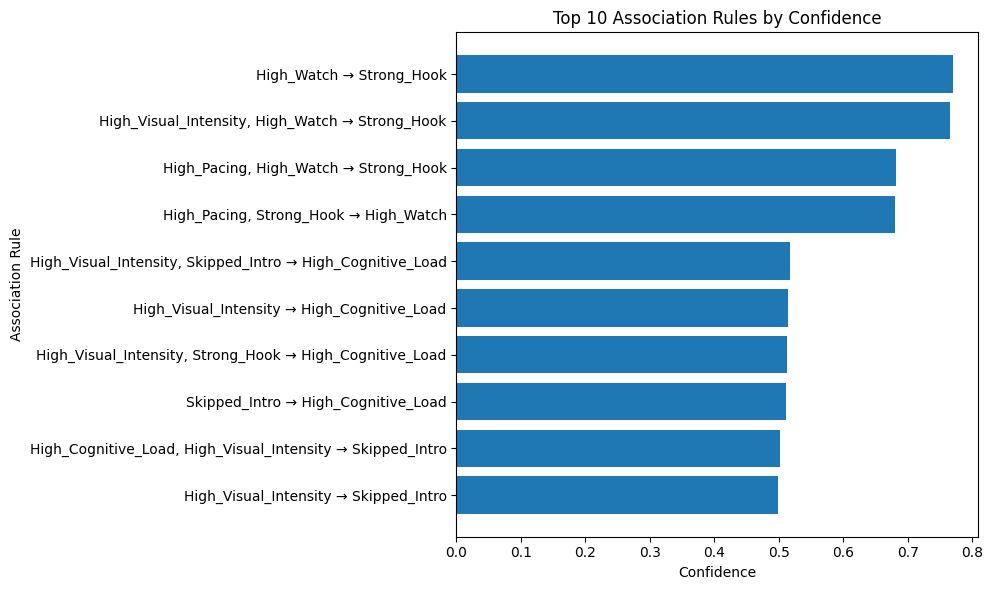

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [26]:
import matplotlib.pyplot as plt

# Create rule labels
final_rules["Rule"] = (
    final_rules["Antecedent"] + " → " + final_rules["Consequent"]
)

# Plot confidence of top 10 rules
plt.figure(figsize=(10, 6))

plt.barh(
    final_rules["Rule"],
    final_rules["confidence"]
)

plt.xlabel("Confidence")
plt.ylabel("Association Rule")
plt.title("Top 10 Association Rules by Confidence")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [27]:
# Find the strongest association rule based on lift

strongest_rule = rules.loc[rules["lift"].idxmax()]

print("Strongest Association Rule:")
print("Antecedent :", strongest_rule["antecedents"])
print("Consequent :", strongest_rule["consequents"])
print("Support    :", round(strongest_rule["support"], 4))
print("Confidence :", round(strongest_rule["confidence"], 4))
print("Lift       :", round(strongest_rule["lift"], 4))

Strongest Association Rule:
Antecedent : frozenset({'High_Watch'})
Consequent : frozenset({'High_Pacing', 'Strong_Hook'})
Support    : 0.0502
Confidence : 0.3058
Lift       : 4.1425


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [28]:
# Final summary of Apriori Association Mining

print("========== EXPERIMENT 9: APRIORI ASSOCIATION MINING ==========")

print("\nDataset:")
print("Total transactions:", len(transaction_matrix))
print("Total behaviour items:", len(transaction_matrix.columns))

print("\nApriori Parameters:")
print("Minimum Support:", 0.05)
print("Minimum Confidence:", 0.30)
print("Minimum Lift:", 1.0)

print("\nResults:")
print("Frequent Itemsets:", len(frequent_itemsets))
print("Positive Association Rules:", len(rules))

print("\nPython implementation completed successfully.")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

========== EXPERIMENT 9: APRIORI ASSOCIATION MINING ==========

Dataset:
Total transactions: 33171
Total behaviour items: 7

Apriori Parameters:
Minimum Support: 0.05
Minimum Confidence: 0.3
Minimum Lift: 1.0

Results:
Frequent Itemsets: 22
Positive Association Rules: 25

Python implementation completed successfully.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [29]:
print("""
Conclusion:
Association rule mining was successfully implemented on the JioHotstar
dataset using the Apriori algorithm in Python. The viewing behaviour
attributes were converted into transaction items and frequent itemsets
were identified using a minimum support of 5%. Association rules were
then generated using a minimum confidence of 30% and positive associations
with lift greater than or equal to 1 were considered. The analysis helped
identify relationships among viewer engagement and content characteristics.
""")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Conclusion:
Association rule mining was successfully implemented on the JioHotstar
dataset using the Apriori algorithm in Python. The viewing behaviour
attributes were converted into transaction items and frequent itemsets
were identified using a minimum support of 5%. Association rules were
then generated using a minimum confidence of 30% and positive associations
with lift greater than or equal to 1 were considered. The analysis helped
identify relationships among viewer engagement and content characteristics.



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [30]:
# Save the transaction matrix for RapidMiner

rapidminer_file = "JioHotstar_Association_Transactions.csv"

transaction_matrix.to_csv(rapidminer_file, index=False)

print("Transaction matrix saved successfully!")
print("File name:", rapidminer_file)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Transaction matrix saved successfully!
File name: JioHotstar_Association_Transactions.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [31]:
from google.colab import files

files.download("JioHotstar_Association_Transactions.csv")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag